In [ ]:
import re                       # expresiones regulares, para interpretar el nombre de cada registro
from pathlib import Path        # manejo de rutas de archivos

import numpy as np              # operaciones numéricas con vectores y matrices
import pandas as pd             # tablas de datos
import matplotlib.pyplot as plt # gráficos
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import wfdb                     # lectura de registros en formato WFDB (PhysioNet)

from scipy import signal

# Carpeta con el dataset. El notebook tiene que estar en la misma carpeta que "Data"
carpeta_data = Path("Data")

# Reducción de interferencias magnetohidrodinámicas en ECG adquiridos durante resonancia magnética

## 1. Carga y caracterización de los registros

Se utiliza la base de datos *Influence of the MHD effect on 12-lead and 3-lead ECGs recorded in 1T to 7T MRI scanners* (Krug Passand, 2021), publicada en PhysioNet (Goldberger et al., 2000). Contiene registros de ECG de sujetos sanos adquiridos dentro de resonadores de 1 T, 3 T y 7 T, sin secuencias de adquisición activas, por lo que la distorsión registrada corresponde principalmente al efecto magnetohidrodinámico (MHD). También incluye registros de referencia adquiridos fuera del resonador.

Los archivos están en formato **WFDB** (*WaveForm DataBase*), el formato estándar de PhysioNet para señales fisiológicas. Cada registro se compone de tres archivos:

- **`.hea` (encabezado):** archivo de texto con la frecuencia de muestreo, la cantidad de derivaciones, sus nombres, unidades y la duración del registro.
- **`.dat` (señal):** los valores muestreados de cada derivación, en formato binario.
- **`.qrs` (anotaciones):** la posición, en muestras, de cada complejo QRS, marcada manualmente por médicos o especialistas en ECG. Se utilizarán como referencia para evaluar la detección automática de latidos.

Para leerlos se utiliza la librería de Python **`wfdb`**, desarrollada por PhysioNet, que interpreta estos formatos y devuelve las señales como matrices de NumPy y las anotaciones como vectores de posiciones.

El nombre de cada registro codifica las condiciones de adquisición. Por ejemplo, `ECGMRI3T04Ff` corresponde a un campo de 3 T, sujeto 04 y posición Ff. Las posiciones son:

- **Hf** (*head first*): el sujeto ingresa al resonador con la cabeza primero.
- **Ff** (*feet first*): ingresa con los pies primero.
- **Pro** y **Sup**: decúbito prono y supino (solo en el resonador de 1 T, de campo vertical).
- **Out**: registro de referencia, fuera del resonador.

Algunos registros tienen un número final (por ejemplo, `ECGMRI3T09Ff1` a `Ff3`), que corresponde a mediciones repetidas en la misma posición.

En esta sección se leen los encabezados y las anotaciones de todos los registros, sin cargar todavía las señales completas, para construir una tabla descriptiva del conjunto.

In [3]:
# El nombre de cada registro tiene la forma ECGMRI<campo>T<sujeto><posición><repetición>.
# La expresión regular separa esas partes:
#   (\d)            -> intensidad del campo en tesla (1, 3 o 7)
#   (\d{2})         -> número de sujeto (dos dígitos)
#   (Ff|Hf|Pro|Sup|Out) -> posición
#   (\d?)           -> número de repetición (opcional)
patron_nombre = re.compile(r"ECGMRI(\d)T(\d{2})(Ff|Hf|Pro|Sup|Out)(\d?)$")

filas = []

# Se recorre cada encabezado (.hea) de la carpeta, ordenados por nombre
for archivo_hea in sorted(carpeta_data.glob("*.hea")):
    nombre = archivo_hea.stem                  # nombre del registro, sin la extensión
    ruta = str(carpeta_data / nombre)          # wfdb recibe la ruta sin extensión

    partes = patron_nombre.match(nombre)
    if partes is None:
        raise ValueError(f"Nombre de registro no reconocido: {nombre}")
    campo, sujeto, posicion, repeticion = partes.groups()

    # rdheader lee solo el encabezado (no la señal), por lo que es rápido
    encabezado = wfdb.rdheader(ruta)

    # rdann lee las anotaciones manuales de QRS (archivo .qrs)
    anotaciones = wfdb.rdann(ruta, "qrs")

    duracion_s = encabezado.sig_len / encabezado.fs

    filas.append({
        "Registro": nombre,
        "Campo (T)": int(campo),
        "Sujeto": f"{campo}T{sujeto}",          # el sujeto se identifica junto con el campo
        "Posición": posicion,
        "Repetición": repeticion or "—",
        "Dentro del resonador": posicion != "Out",
        "Frecuencia (Hz)": encabezado.fs,
        "Derivaciones": encabezado.n_sig,
        "Nombres de derivaciones": ", ".join(encabezado.sig_name),
        "Unidades": ", ".join(sorted(set(encabezado.units))),
        "Duración (s)": round(duracion_s, 1),
        "QRS anotados": len(anotaciones.sample),
        # Frecuencia cardíaca media aproximada a partir de las anotaciones
        "FC media (lpm)": round(60 * len(anotaciones.sample) / duracion_s, 1),
    })

registros = pd.DataFrame(filas)

print(f"Registros leídos: {len(registros)}")
print(f"Duración total: {registros['Duración (s)'].sum() / 60:.1f} minutos")
display(registros)

Registros leídos: 53
Duración total: 226.6 minutos


,Registro,Campo (T),Sujeto,Posición,Repetición,Dentro del resonador,Frecuencia (Hz),Derivaciones,Nombres de derivaciones,Unidades,Duración (s),QRS anotados,FC media (lpm)
0,ECGMRI1T01Out,1,1T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,29.3,44,90.1
1,ECGMRI1T01Pro,1,1T01,Pro,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,39.1,57,87.6
2,ECGMRI1T01Sup,1,1T01,Sup,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,26.4,38,86.5
3,ECGMRI3T01Ff,3,3T01,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,326.2,361,66.4
4,ECGMRI3T01Hf,3,3T01,Hf,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,366.2,400,65.5
5,ECGMRI3T01Out,3,3T01,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,156.2,171,65.7
6,ECGMRI3T02Ff,3,3T02,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
7,ECGMRI3T02Out,3,3T02,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,24.4,27,66.4
8,ECGMRI3T03Ff,3,3T03,Ff,—,True,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,195.3,186,57.1
9,ECGMRI3T03Out,3,3T03,Out,—,False,1024,12,"I, II, III, aVR, aVL, aVF, V1, V2, V3, V4, V5, V6",mV,127.0,119,56.2


In [4]:
# Cantidad de registros según el campo magnético y la posición
print("Registros por campo y posición:")
display(pd.crosstab(registros["Campo (T)"], registros["Posición"], margins=True, margins_name="Total"))

# Cantidad de registros según la cantidad de derivaciones (equipo de 3 o de 12 derivaciones)
print("Registros por cantidad de derivaciones:")
display(registros["Derivaciones"].value_counts().rename("Registros"))

# Sujetos que tienen al menos un registro dentro del resonador y uno de
# referencia fuera. Son los que permiten comparar el ECG del mismo sujeto
# con y sin efecto MHD
con_referencia = (
    registros.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()

print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,5,5,5,0,0,15
Total,30,11,10,1,1,53


Registros por cantidad de derivaciones:


Derivaciones
12    39
3     14
Name: Registros, dtype: int64

Sujetos con registro dentro y fuera del resonador: 10
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T04', '7T05']


### Control de registros duplicados

En la tabla descriptiva, los registros del sujeto 7T04 presentan exactamente la misma duración, cantidad de QRS anotados y frecuencia cardíaca que los del sujeto 3T01, en las tres posiciones. Lo mismo ocurre entre los registros 3T02Ff y 3T02Out. Como es muy poco probable que dos mediciones distintas coincidan en estos tres valores, se verifica si los archivos son copias.

Para eso se calcula una huella digital (hash SHA-256) del contenido de cada archivo de señal (`.dat`) y de anotaciones (`.qrs`). El hash es un código que se obtiene a partir de todos los bytes del archivo: dos archivos con el mismo contenido producen exactamente el mismo código, y cualquier diferencia, aunque sea de un solo valor, produce un código distinto. Así se puede comprobar si dos registros son idénticos sin comparar las señales muestra por muestra.

In [5]:
import hashlib  # cálculo de huellas digitales (hash) de archivos

# Nombres de los registros (sirve tanto si la tabla tiene el nombre como
# columna como si lo tiene como índice)
nombres = (
    list(registros["Registro"]) if "Registro" in registros.columns
    else list(registros.index)
)


def huella(archivo):
    """Hash SHA-256 de todos los bytes del archivo."""
    return hashlib.sha256(archivo.read_bytes()).hexdigest()


huellas_senal = [huella(carpeta_data / f"{n}.dat") for n in nombres]
huellas_qrs = [huella(carpeta_data / f"{n}.qrs") for n in nombres]

# Agrupar los registros que comparten la misma huella
for tipo, huellas in [("señal (.dat)", huellas_senal), ("anotaciones (.qrs)", huellas_qrs)]:
    grupos = pd.Series(nombres).groupby(huellas).apply(list)
    repetidos = grupos[grupos.apply(len) > 1]

    print(f"Grupos de registros con {tipo} idénticas: {len(repetidos)}")
    for lista in repetidos:
        print("   " + " = ".join(lista))
    print()

Grupos de registros con señal (.dat) idénticas: 1
   ECGMRI3T01Out = ECGMRI7T04Out

Grupos de registros con anotaciones (.qrs) idénticas: 3
   ECGMRI3T01Hf = ECGMRI7T04Hf
   ECGMRI3T01Ff = ECGMRI7T04Ff
   ECGMRI3T01Out = ECGMRI7T04Out



El registro `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`. Los registros `ECGMRI7T04Ff` y `ECGMRI7T04Hf` tienen las mismas anotaciones que `ECGMRI3T01Ff` y `ECGMRI3T01Hf`, aunque sus archivos de señal no son idénticos. Como dos sesiones distintas no pueden presentar los latidos exactamente en las mismas posiciones, se comparan las señales de cada par para determinar si corresponden a la misma grabación.

Para cada par se calcula la **correlación de Pearson** entre las señales, derivación por derivación. Mide qué tan parecida es la forma de dos señales, independientemente de su escala: vale 1 si una es copia de la otra (aunque esté multiplicada por una constante) y valores cercanos a 0 si no se parecen. También se calcula la diferencia máxima entre ambas, en mV.

In [6]:
# Pares de registros a comparar
pares = [
    ("ECGMRI3T01Ff", "ECGMRI7T04Ff"),
    ("ECGMRI3T01Hf", "ECGMRI7T04Hf"),
    ("ECGMRI3T01Out", "ECGMRI7T04Out"),
    ("ECGMRI3T02Ff", "ECGMRI3T02Out"),
]

filas_pares = []
for nombre_a, nombre_b in pares:
    # rdrecord lee la señal completa; p_signal es la matriz (muestras x derivaciones) en mV
    a = wfdb.rdrecord(str(carpeta_data / nombre_a)).p_signal
    b = wfdb.rdrecord(str(carpeta_data / nombre_b)).p_signal

    # Si tienen distinta longitud, se comparan solo las muestras en común
    n = min(len(a), len(b))
    a, b = a[:n], b[:n]

    # Correlación de cada derivación entre ambos registros
    correlaciones = [np.corrcoef(a[:, i], b[:, i])[0, 1] for i in range(a.shape[1])]

    filas_pares.append({
        "Registro A": nombre_a,
        "Registro B": nombre_b,
        "Muestras comparadas": n,
        "Correlación mínima": min(correlaciones),
        "Correlación media": np.mean(correlaciones),
        "Diferencia máxima (mV)": np.nanmax(np.abs(a - b)),
    })

display(pd.DataFrame(filas_pares).round(4))

,Registro A,Registro B,Muestras comparadas,Correlación mínima,Correlación media,Diferencia máxima (mV)
0,ECGMRI3T01Ff,ECGMRI7T04Ff,334001,0.9352,0.9485,7.7055
1,ECGMRI3T01Hf,ECGMRI7T04Hf,375001,0.9219,0.9455,17.5597
2,ECGMRI3T01Out,ECGMRI7T04Out,160000,1.0000,1.0000,0.0000
3,ECGMRI3T02Ff,ECGMRI3T02Out,25000,-0.1159,-0.0079,3.7222


In [7]:
# Registros excluidos: los tres de 7T04 duplican la sesión de 3T01
# (7T04Out es una copia exacta y 7T04Ff/7T04Hf comparten las anotaciones
# y tienen correlación > 0,92 con 3T01Ff/3T01Hf)
excluidos = ["ECGMRI7T04Ff", "ECGMRI7T04Hf", "ECGMRI7T04Out"]

registros["Excluido"] = [n in excluidos for n in nombres]
registros_validos = registros[~registros["Excluido"]].copy()

dentro = registros_validos["Dentro del resonador"]
print(f"Registros válidos: {len(registros_validos)} "
      f"({dentro.sum()} dentro y {(~dentro).sum()} fuera del resonador)")

# Comprobación con la descripción de PhysioNet (43 registros dentro, 203 minutos),
# usando la tabla completa, antes de excluir
dentro_total = registros["Dentro del resonador"]
print(f"Duración de los registros dentro del resonador (tabla completa): "
      f"{registros.loc[dentro_total, 'Duración (s)'].sum() / 60:.1f} min "
      f"en {dentro_total.sum()} registros")

print("\nRegistros válidos por campo y posición:")
display(pd.crosstab(registros_validos["Campo (T)"], registros_validos["Posición"],
                    margins=True, margins_name="Total"))

con_referencia = (
    registros_validos.groupby("Sujeto")["Dentro del resonador"]
    .agg(lambda x: x.any() and (~x).any())
)
sujetos_pareados = con_referencia[con_referencia].index.tolist()
print(f"Sujetos con registro dentro y fuera del resonador: {len(sujetos_pareados)}")
print(sujetos_pareados)

Registros válidos: 50 (41 dentro y 9 fuera del resonador)
Duración de los registros dentro del resonador (tabla completa): 203.1 min en 43 registros

Registros válidos por campo y posición:


Posición,Ff,Hf,Out,Pro,Sup,Total
Campo (T),,,,,,
1,0,0,1,1,1,3
3,25,6,4,0,0,35
7,4,4,4,0,0,12
Total,29,10,9,1,1,50


Sujetos con registro dentro y fuera del resonador: 9
['1T01', '3T01', '3T02', '3T03', '3T04', '7T01', '7T02', '7T03', '7T05']


### Resultado de la caracterización de los registros

El conjunto contiene 53 registros, todos muestreados a 1024 Hz y con las señales expresadas en mV:

- 43 registros dentro del resonador, con una duración total de 203,1 minutos, que coincide con la descripción de PhysioNet, y 10 registros de referencia fuera del resonador.
- 39 registros de 12 derivaciones (I, II, III, aVR, aVL, aVF y V1 a V6), adquiridos con el Holter CardioMem 3000, y 14 de 3 derivaciones (I, II y III), adquiridos con el monitor inalámbrico del equipo de resonancia (Tesla M3). Los de 3 derivaciones corresponden a los sujetos 3T10 a 3T23, todos en posición Ff y sin registro de referencia.
- Los registros a 1 T son cortos (26 a 39 s), mientras que los de 3 T y 7 T duran entre 24 s y 12 minutos. La frecuencia cardíaca media, estimada a partir de las anotaciones, varía entre 46 y 90 lpm.

**Registros duplicados:** El control de huellas digitales mostró que `ECGMRI7T04Out` es una copia exacta de `ECGMRI3T01Out`, y que `ECGMRI7T04Ff` y `ECGMRI7T04Hf` comparten las anotaciones de `ECGMRI3T01Ff` y `ECGMRI3T01Hf`. Sus señales presentan una correlación de entre 0,92 y 0,95 con los latidos alineados muestra a muestra, lo que no es posible entre sesiones distintas (como referencia, los registros 3T02Ff y 3T02Out, que sí son sesiones distintas, tienen una correlación cercana a 0). Por lo tanto, corresponden a una misma sesión. Se excluyen los tres registros de 7T04 y se conservan los de 3T01, ya que la serie de 3 T es consecutiva (sujetos 01 a 23) y coincide con los 23 sujetos informados en el dataset. Como no es posible confirmar cuál de las dos etiquetas de campo es la correcta, esto se considera una limitación del trabajo.

Quedan 50 registros válidos y 9 sujetos con registro dentro y fuera del resonador, que se utilizarán para comparar la morfología del ECG con y sin efecto MHD. Los 50 registros, al tener anotaciones manuales de QRS, se utilizarán para evaluar la detección de latidos.

## 2. Caracterización temporal y frecuencial

Se caracterizan las señales originales, antes de aplicar filtros,
mediante media, varianza, valor RMS, autocorrelación y densidad
espectral de potencia (PSD).

### Caracterización temporal

La media describe el nivel medio del registro. La varianza cuantifica
las fluctuaciones alrededor de ese nivel y el RMS representa la
amplitud cuadrática media. Se calculan sobre cada derivación del
registro completo, conservando las unidades físicas de adquisición.

Estas medidas describen la señal observada en su conjunto: no permiten
separar la actividad cardíaca, el efecto MHD y otras fuentes de ruido.
Por lo tanto, un aumento de varianza o RMS no se interpreta por sí
solo como una medida de interferencia MHD.

La autocorrelación se calcula sobre la señal centrada y se normaliza
por su valor a retardo cero. Se utiliza para explorar la repetitividad
temporal. Una estructura periódica no implica ausencia de interferencia,
ya que el efecto MHD también está relacionado con el ciclo cardíaco.

### Estimación de la densidad espectral de potencia

La PSD se estima mediante el método de Welch, que divide la señal en
segmentos, calcula sus periodogramas modificados y los promedia para
reducir la variabilidad de la estimación espectral (Welch, 1967).

Se utiliza una ventana Hann para reducir la fuga espectral respecto
del truncamiento rectangular. Esta reducción se obtiene a costa de
ensanchar el lóbulo principal y disminuir la capacidad de distinguir
componentes frecuenciales próximas (Harris, 1978).

Se adoptan segmentos de 4 segundos con un solapamiento del 50 %.
Como antecedente aplicado al voltaje del ECG, Ishmakhametov et al.
(2026) utilizaron Welch con ventanas Hann de 2048 muestras a 512 Hz,
equivalentes a 4 segundos, y un solapamiento del 50 %, para estimar
la PSD en una evaluación de calidad de señales fisiológicas.

En nuestro caso, se conserva esa duración temporal y se adapta la
cantidad de muestras a la frecuencia de muestreo del dataset:

N_segmento = 4 s × 1024 muestras/s = 4096 muestras.

El solapamiento corresponde a 2048 muestras y el desplazamiento
entre segmentos consecutivos es de 2 segundos.

Sin relleno con ceros, la separación entre bins es:

Δf = fs / N_segmento = 1024 / 4096 = 0,25 Hz.

Esta separación no equivale a la resolución espectral efectiva,
que también depende de la ventana.

La duración de 4 segundos permite calcular varios periodogramas
incluso en los registros más cortos del conjunto. Se adopta como
configuración inicial respaldada por un antecedente de ECG,
sin considerarla una duración óptima demostrada para este dataset.

El solapamiento permite incorporar segmentos adicionales al promedio,
aunque estos no constituyen observaciones estadísticamente
independientes.

Para calcular la PSD se elimina la media de cada segmento antes
del enventanado. Este centrado se aplica únicamente a la estimación
espectral; las estadísticas temporales se calculan sobre las señales
originales. La PSD se expresa en mV²/Hz.

### Comparación entre condiciones

Se mantienen los mismos parámetros de estimación en todos los
registros y derivaciones.

Las comparaciones dentro–fuera se realizan entre registros del mismo
identificador de sujeto y con derivaciones coincidentes. Para las
figuras comparativas se utilizan tramos iniciales de igual duración,
de hasta 30 segundos, limitados por el registro más corto del par.
Este criterio es reproducible, pero requiere inspeccionar los tramos
para identificar posibles transitorios o artefactos.

Las estadísticas generales describen los registros completos.
Las tablas que acompañan a las figuras describen únicamente
los tramos representados.

Las señales temporales no están alineadas por latidos, por lo que
no se interpreta su diferencia muestra a muestra. La alineación
y el análisis morfológico se abordarán en una etapa posterior.

Las referencias externas no son simultáneas con las adquisiciones
internas. Por ello, las diferencias temporales y espectrales no se
atribuyen exclusivamente al MHD (Krug et al., 2017).

Abi-Abdallah et al. (2007) constituye un antecedente directo de
comparación temporal y espectral de ECG dentro y fuera de un
resonador mediante Welch. Ese trabajo no especifica la ventana,
la duración de los segmentos ni el solapamiento, por lo que no
se utiliza para justificar esos parámetros.


In [9]:
# Configuración de Welch:
# Hann de 4 s y 50 % de solapamiento.
VENTANA_S = 4.0
SOLAPAMIENTO = 0.50


def estadisticas_temporales(x):
    """Estadísticas descriptivas sobre la señal original."""
    x = np.asarray(x, dtype=float)

    if (x.ndim != 1 or len(x) == 0) or (not np.isfinite(x).all()):
        raise ValueError("Error en la señal: debe ser unidimensional, no vacía y finita.")

    return {
        "Media (mV)": np.mean(x),
        "Varianza (mV²)": np.var(x, ddof=0),
        "RMS (mV)": np.sqrt(np.mean(x**2)),
    }


def calcular_psd(x, fs):
    """PSD unilateral de Welch, expresada en mV²/Hz."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional y finita.")

    nperseg = int(round(VENTANA_S * fs))
    noverlap = int(round(nperseg * SOLAPAMIENTO))

    if len(x) < nperseg:
        raise ValueError(
            f"Se necesitan al menos {nperseg} muestras "
            f"para una ventana de {VENTANA_S} s."
        )

    # Hann periódica, adecuada para análisis mediante DFT.
    ventana = signal.windows.hann(nperseg, sym=False)

    f, psd = signal.welch(
        x,
        fs=fs,
        window=ventana,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nperseg,             # Sin relleno con ceros
        detrend="constant",       # Restar media antes del enventanado
        return_onesided=True,
        scaling="density",
        average="mean",
    )

    paso = nperseg - noverlap
    cantidad_segmentos = 1 + (len(x) - nperseg) // paso

    return f, psd, cantidad_segmentos


def calcular_autocorrelacion(x, fs, max_retardo_s=3.0):
    """Autocorrelación sesgada, centrada y normalizada en retardo cero."""
    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or len(x) == 0 or not np.isfinite(x).all():
        raise ValueError("La señal debe ser unidimensional, no vacía y finita.")

    centrada = x - np.mean(x)
    energia = np.dot(centrada, centrada)

    n_retardos = min(
        len(x),
        int(round(max_retardo_s * fs)) + 1,
    )
    retardos = np.arange(n_retardos) / fs

    # Una señal constante no tiene autocorrelación normalizada definida.
    if energia == 0:
        return retardos, np.full(n_retardos, np.nan)

    correlacion = signal.correlate(
        centrada,
        centrada,
        mode="full",
        method="fft",
    )

    correlacion = correlacion[
        len(x) - 1:len(x) - 1 + n_retardos
    ]

    # El factor 1/N se cancela al normalizar por el retardo cero.
    normalizada = correlacion / energia

    return retardos, normalizada

In [10]:
filas_caracteristicas = []
espectros = {}

for _, fila in registros_validos.iterrows():
    nombre = fila["Registro"]
    registro = wfdb.rdrecord(str(carpeta_data / nombre))

    fs = float(registro.fs)

    if registro.p_signal is None:
        raise ValueError(f"{nombre}: no se pudieron cargar las señales físicas.")

    for canal, derivacion in enumerate(registro.sig_name):
        unidad = registro.units[canal]

        # Las etiquetas y comparaciones de este análisis utilizan mV.
        if unidad != "mV":
            raise ValueError(
                f"{nombre}, {derivacion}: unidad inesperada '{unidad}'."
            )

        x = np.asarray(registro.p_signal[:, canal], dtype=float)

        try:
            estadisticas = estadisticas_temporales(x)
            f, psd, cantidad_segmentos = calcular_psd(x, fs)
        except ValueError as error:
            raise ValueError(
                f"Error en {nombre}, derivación {derivacion}: {error}"
            ) from error

        filas_caracteristicas.append({
            "Registro": nombre,
            "Sujeto": fila["Sujeto"],
            "Campo de la serie (T)": fila["Campo (T)"],
            "Posición": fila["Posición"],
            "Dentro del resonador": fila["Dentro del resonador"],
            "Derivación": derivacion,
            "Frecuencia de muestreo (Hz)": fs,
            "Duración (s)": len(x) / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        espectros[(nombre, derivacion)] = {
            "Frecuencia (Hz)": f,
            "PSD (mV²/Hz)": psd,
        }

caracteristicas = pd.DataFrame(filas_caracteristicas)

print(
    f"Registros caracterizados: "
    f"{caracteristicas['Registro'].nunique()}"
)
print(f"Combinaciones registro–derivación: {len(caracteristicas)}")

display(caracteristicas.round(4))

Registros caracterizados: 50
Combinaciones registro–derivación: 474


,Registro,Sujeto,Campo de la serie (T),Posición,Dentro del resonador,Derivación,Frecuencia de muestreo (Hz),Duración (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,ECGMRI1T01Out,1T01,1,Out,False,I,1024.0,29.2959,-0.0933,0.0087,0.1321,13
1,ECGMRI1T01Out,1T01,1,Out,False,II,1024.0,29.2959,5.9921,0.0761,5.9985,13
2,ECGMRI1T01Out,1T01,1,Out,False,III,1024.0,29.2959,0.0848,0.0405,0.2185,13
3,ECGMRI1T01Out,1T01,1,Out,False,aVR,1024.0,29.2959,-14.9500,0.0323,14.9511,13
4,ECGMRI1T01Out,1T01,1,Out,False,aVL,1024.0,29.2959,-6.0891,0.0056,6.0895,13
...,...,...,...,...,...,...,...,...,...,...,...,...
469,ECGMRI7T05Out,7T05,7,Out,False,V2,1024.0,107.4229,0.0000,0.1342,0.3664,52
470,ECGMRI7T05Out,7T05,7,Out,False,V3,1024.0,107.4229,0.0000,0.1312,0.3622,52
471,ECGMRI7T05Out,7T05,7,Out,False,V4,1024.0,107.4229,-0.0000,0.1794,0.4236,52
472,ECGMRI7T05Out,7T05,7,Out,False,V5,1024.0,107.4229,0.0000,0.1177,0.3430,52


In [22]:
# Resumen de las estadísticas de todos los registros y derivaciones.
metricas = ["Media (mV)", "Varianza (mV²)", "RMS (mV)"]

estadisticas_globales = caracteristicas.copy()

numero_derivaciones = (
    registros_validos.set_index("Registro")["Derivaciones"]
)

estadisticas_globales["Derivaciones"] = (
    estadisticas_globales["Registro"].map(numero_derivaciones)
)

estadisticas_globales["Condición"] = np.where(
    estadisticas_globales["Dentro del resonador"],
    "Dentro",
    "Fuera",
)

grupos = estadisticas_globales.groupby(
    ["Derivaciones", "Derivación", "Condición"]
)

resumen_global = pd.concat(
    [
        grupos.size().rename("Cantidad"),
        grupos[metricas].median().add_suffix(" — Mediana"),
        grupos[metricas].quantile(0.25).add_suffix(" — Q25"),
        grupos[metricas].quantile(0.75).add_suffix(" — Q75"),
    ],
    axis=1,
).reset_index()

# Mostrar una tabla por métrica para facilitar su lectura.
for metrica in metricas:
    print(f"\nResumen de {metrica}")

    columnas = [
        "Derivaciones",
        "Derivación",
        "Condición",
        "Cantidad",
        f"{metrica} — Mediana",
        f"{metrica} — Q25",
        f"{metrica} — Q75",
    ]

    display(resumen_global[columnas].round(4))


Resumen de Media (mV)


,Derivaciones,Derivación,Condición,Cantidad,Media (mV) — Mediana,Media (mV) — Q25,Media (mV) — Q75
0,3,I,Dentro,14,-1.1593,-2.5902,2.2159
1,3,II,Dentro,14,0.0922,-3.2875,3.5185
2,3,III,Dentro,14,0.1537,-2.2869,0.9641
3,12,I,Dentro,27,0.0000,-0.0034,0.0086
4,12,I,Fuera,9,-0.0000,-0.0088,0.0000
5,12,II,Dentro,27,0.0000,-0.0000,0.0154
6,12,II,Fuera,9,-0.0000,-0.0000,-0.0000
7,12,III,Dentro,27,0.0000,-0.0002,0.0084
8,12,III,Fuera,9,0.0000,-0.0000,0.0176
9,12,V1,Dentro,27,0.0000,-0.0108,0.0075



Resumen de Varianza (mV²)


,Derivaciones,Derivación,Condición,Cantidad,Varianza (mV²) — Mediana,Varianza (mV²) — Q25,Varianza (mV²) — Q75
0,3,I,Dentro,14,0.0548,0.0393,0.1091
1,3,II,Dentro,14,0.1990,0.1430,0.3387
2,3,III,Dentro,14,0.0836,0.0536,0.1286
3,12,I,Dentro,27,0.8732,0.5749,1.9683
4,12,I,Fuera,9,0.0116,0.0087,0.0137
5,12,II,Dentro,27,0.8654,0.6325,1.5066
6,12,II,Fuera,9,0.1063,0.0761,0.1253
7,12,III,Dentro,27,1.1641,0.7145,2.5547
8,12,III,Fuera,9,0.0592,0.0405,0.0676
9,12,V1,Dentro,27,0.3551,0.2479,1.0765



Resumen de RMS (mV)


,Derivaciones,Derivación,Condición,Cantidad,RMS (mV) — Mediana,RMS (mV) — Q25,RMS (mV) — Q75
0,3,I,Dentro,14,2.6473,1.3964,6.1057
1,3,II,Dentro,14,3.6999,2.3753,4.4858
2,3,III,Dentro,14,1.5201,0.9463,3.0517
3,12,I,Dentro,27,0.9345,0.7599,1.4016
4,12,I,Fuera,9,0.1114,0.0938,0.1321
5,12,II,Dentro,27,0.9330,0.7960,1.3603
6,12,II,Fuera,9,0.3274,0.3047,0.4006
7,12,III,Dentro,27,1.0789,0.8467,1.5984
8,12,III,Fuera,9,0.2434,0.2185,0.2601
9,12,V1,Dentro,27,0.5961,0.4985,1.0372


In [24]:
claves = ["Sujeto", "Derivación", "Derivaciones"]

referencias = (
    estadisticas_globales.loc[
        ~estadisticas_globales["Dentro del resonador"],
        claves + ["Registro"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro fuera",
        **{metrica: f"{metrica} fuera" for metrica in metricas},
    })
)

internos = (
    estadisticas_globales.loc[
        estadisticas_globales["Dentro del resonador"],
        claves + ["Registro", "Posición"] + metricas,
    ]
    .rename(columns={
        "Registro": "Registro dentro",
        **{metrica: f"{metrica} dentro" for metrica in metricas},
    })
)

# Se espera una sola referencia externa por sujeto y derivación.
comparaciones_pareadas = internos.merge(
    referencias,
    on=claves,
    how="inner",
    validate="many_to_one",
)

comparaciones_pareadas["Diferencia de media (mV)"] = (
    comparaciones_pareadas["Media (mV) dentro"]
    - comparaciones_pareadas["Media (mV) fuera"]
)

for metrica, nombre in [
    ("Varianza (mV²)", "Cociente varianza dentro/fuera"),
    ("RMS (mV)", "Cociente RMS dentro/fuera"),
]:
    denominador = comparaciones_pareadas[f"{metrica} fuera"]

    comparaciones_pareadas[nombre] = (
        comparaciones_pareadas[f"{metrica} dentro"]
        / denominador.where(denominador > 0)
    )

columnas_mostrar = [
    "Registro dentro",
    "Registro fuera",
    "Derivación",
    "Diferencia de media (mV)",
    "Cociente varianza dentro/fuera",
    "Cociente RMS dentro/fuera",
]

display(
    comparaciones_pareadas[columnas_mostrar]
    .round(4)
    .reset_index(drop=True)
)

,Registro dentro,Registro fuera,Derivación,Diferencia de media (mV),Cociente varianza dentro/fuera,Cociente RMS dentro/fuera
0,ECGMRI1T01Pro,ECGMRI1T01Out,I,0.0285,46.8930,4.8720
1,ECGMRI1T01Pro,ECGMRI1T01Out,II,0.2087,14.9571,1.0489
2,ECGMRI1T01Pro,ECGMRI1T01Out,III,0.1802,15.4973,3.8253
3,ECGMRI1T01Pro,ECGMRI1T01Out,aVR,-0.1186,19.1073,1.0092
4,ECGMRI1T01Pro,ECGMRI1T01Out,aVL,-0.0763,41.8918,1.0156
...,...,...,...,...,...,...
175,ECGMRI7T05Hf,ECGMRI7T05Out,V2,0.0000,13.9179,3.7307
176,ECGMRI7T05Hf,ECGMRI7T05Out,V3,-0.0000,11.7248,3.4242
177,ECGMRI7T05Hf,ECGMRI7T05Out,V4,-0.0000,8.7936,2.9654
178,ECGMRI7T05Hf,ECGMRI7T05Out,V5,-0.0000,12.5725,3.5458


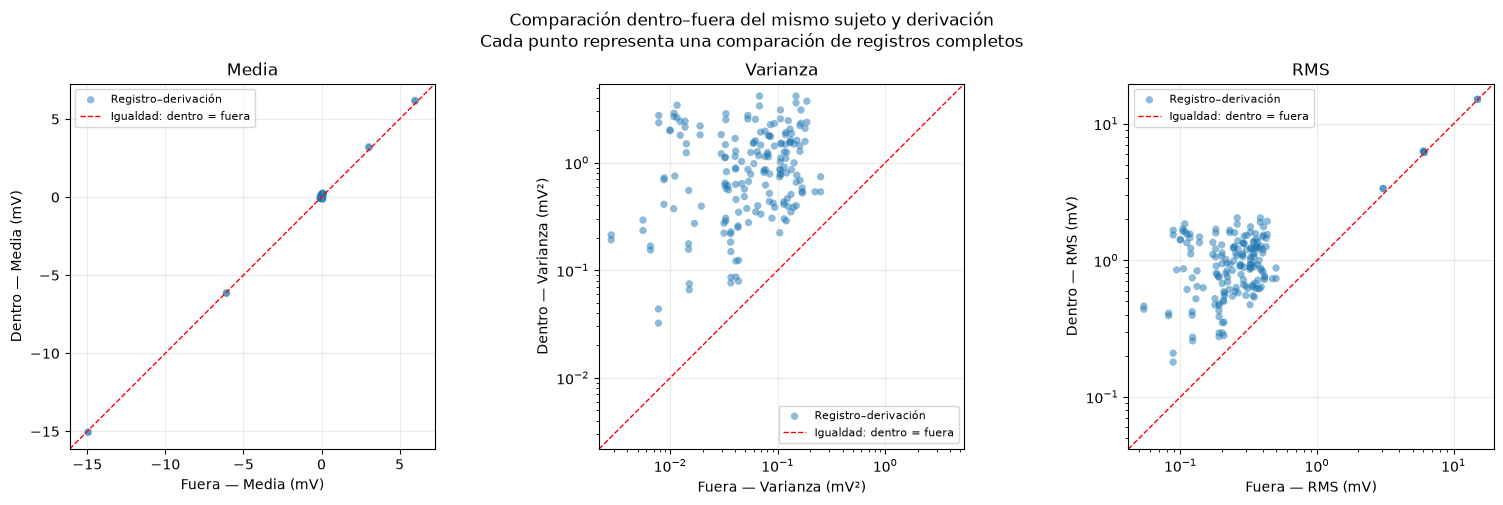

In [28]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))

configuracion = [
    ("Media (mV)", "Media", False),
    ("Varianza (mV²)", "Varianza", True),
    ("RMS (mV)", "RMS", True),
]

for ax, (metrica, titulo, usar_log) in zip(ejes, configuracion):
    x = comparaciones_pareadas[f"{metrica} fuera"].to_numpy(dtype=float)
    y = comparaciones_pareadas[f"{metrica} dentro"].to_numpy(dtype=float)

    validos = np.isfinite(x) & np.isfinite(y)

    if usar_log:
        validos &= (x > 0) & (y > 0)

    x, y = x[validos], y[validos]

    if len(x) == 0:
        ax.set_title(titulo)
        ax.text(
            0.5, 0.5, "Sin valores disponibles",
            ha="center", transform=ax.transAxes,
        )
        continue

    ax.scatter(
        x, y,
        s=28,
        alpha=0.5,
        edgecolors="none",
        label="Registro–derivación",
    )

    valores = np.concatenate([x, y])

    if usar_log:
        minimo = valores.min() / 1.3
        maximo = valores.max() * 1.3
        ax.set_xscale("log")
        ax.set_yscale("log")
    else:
        minimo, maximo = valores.min(), valores.max()
        margen = max((maximo - minimo) * 0.05, 0.01)
        minimo -= margen
        maximo += margen

    # Igualdad y mismos límites en ambos ejes.
    ax.plot(
        [minimo, maximo],
        [minimo, maximo],
        "r--",
        linewidth=1,
        label="Igualdad: dentro = fuera",
    )

    ax.set_xlim(minimo, maximo)
    ax.set_ylim(minimo, maximo)
    ax.set_aspect("equal", adjustable="box")

    ax.set(
        title=titulo,
        xlabel=f"Fuera — {metrica}",
        ylabel=f"Dentro — {metrica}",
    )

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Comparación dentro–fuera del mismo sujeto y derivación\n"
    "Cada punto representa una comparación de registros completos"
)

plt.tight_layout()
# plt.show()

La comparación pareada muestra medias similares dentro y fuera
del resonador, con puntos próximos a la recta de igualdad.
En cambio, todas las comparaciones presentan mayor varianza
y RMS en la adquisición interna.

El cociente de varianzas presenta una mediana de 13,88 y el
cociente de RMS una mediana de 3,45. Estos resultados indican
mayores fluctuaciones y mayor amplitud cuadrática media dentro
del resonador, sin un desplazamiento generalizado del nivel medio.

En algunas derivaciones con niveles medios elevados, el RMS
permanece próximo a la igualdad, dado que esta medida incluye
la contribución de la media: RMS² = varianza + media².
Por ello, la varianza resulta más directa para describir
las fluctuaciones alrededor del nivel medio.

Los resultados son descriptivos y corresponden a adquisiciones
no simultáneas de distinta duración. No permiten atribuir todo
el incremento exclusivamente al MHD. Las comparaciones comparten
sujetos y referencias, por lo que no son observaciones independientes.

In [11]:
def comparar_registros(
    nombre_fuera,
    nombre_dentro,
    derivacion="II",
    duracion_max_s=30.0,
):
    """Compara registros del mismo grupo, sin filtrar ni alinear latidos."""

    tabla = registros_validos.set_index("Registro")

    for nombre in (nombre_fuera, nombre_dentro):
        if nombre not in tabla.index:
            raise ValueError(
                f"{nombre} no pertenece al conjunto de registros conservados."
            )

    fila_fuera = tabla.loc[nombre_fuera]
    fila_dentro = tabla.loc[nombre_dentro]

    if bool(fila_fuera["Dentro del resonador"]):
        raise ValueError("El primer registro debe ser una referencia Out.")

    if not bool(fila_dentro["Dentro del resonador"]):
        raise ValueError("El segundo registro debe estar dentro del resonador.")

    if fila_fuera["Sujeto"] != fila_dentro["Sujeto"]:
        raise ValueError("Los registros deben pertenecer al mismo grupo.")

    if fila_fuera["Derivaciones"] != fila_dentro["Derivaciones"]:
        raise ValueError("Los registros tienen configuraciones diferentes.")

    fuera = wfdb.rdrecord(str(carpeta_data / nombre_fuera))
    dentro = wfdb.rdrecord(str(carpeta_data / nombre_dentro))

    if fuera.fs != dentro.fs:
        raise ValueError("Las frecuencias de muestreo no coinciden.")

    if (
        derivacion not in fuera.sig_name
        or derivacion not in dentro.sig_name
    ):
        raise ValueError(
            f"La derivación {derivacion} no está disponible en ambos registros."
        )

    canal_fuera = fuera.sig_name.index(derivacion)
    canal_dentro = dentro.sig_name.index(derivacion)

    if (
        fuera.units[canal_fuera] != "mV"
        or dentro.units[canal_dentro] != "mV"
    ):
        raise ValueError("Ambas señales deben estar expresadas en mV.")

    fs = float(fuera.fs)

    if not np.isfinite(duracion_max_s) or duracion_max_s < VENTANA_S:
        raise ValueError(
            f"La duración solicitada debe ser al menos {VENTANA_S} s."
        )

    n = min(
        len(fuera.p_signal),
        len(dentro.p_signal),
        int(round(duracion_max_s * fs)),
    )

    datos = {
        "Fuera": np.asarray(
            fuera.p_signal[:n, canal_fuera], dtype=float
        ),
        "Dentro": np.asarray(
            dentro.p_signal[:n, canal_dentro], dtype=float
        ),
    }

    # Validar y calcular antes de crear la figura.
    resultados = {}
    filas_resumen = []

    for condicion, x in datos.items():
        estadisticas = estadisticas_temporales(x)
        f, psd, cantidad_segmentos = calcular_psd(x, fs)
        retardos, autocorr = calcular_autocorrelacion(x, fs)

        resultados[condicion] = {
            "Señal": x,
            "Frecuencia": f,
            "PSD": psd,
            "Retardos": retardos,
            "Autocorrelación": autocorr,
        }

        filas_resumen.append({
            "Condición": condicion,
            "Duración analizada (s)": n / fs,
            **estadisticas,
            "Segmentos Welch": cantidad_segmentos,
        })

        if np.isnan(autocorr).all():
            print(
                f"Aviso: {condicion} presenta una señal constante; "
                "su autocorrelación normalizada no está definida."
            )

    colores = {"Fuera": "tab:blue", "Dentro": "tab:orange"}

    fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
    tiempo = np.arange(n) / fs
    n_vista = min(n, int(round(5 * fs)))

    for condicion, resultado in resultados.items():
        color = colores[condicion]

        ejes[0, 0].plot(
            tiempo[:n_vista],
            resultado["Señal"][:n_vista],
            color=color,
            label=condicion,
            alpha=0.8,
            linewidth=1,
        )

        ejes[0, 1].plot(
            resultado["Retardos"],
            resultado["Autocorrelación"],
            color=color,
            label=condicion,
        )

        f = resultado["Frecuencia"]
        psd = resultado["PSD"]

        # Los ceros se omiten únicamente en la representación logarítmica.
        for eje, limite in ((ejes[1, 0], 100), (ejes[1, 1], 20)):
            mascara = (f <= limite) & (psd > 0)

            eje.semilogy(
                f[mascara],
                psd[mascara],
                color=color,
                label=condicion,
            )
            eje.set_xlim(0, min(limite, fs / 2))

    ejes[0, 0].set(
        title="ECG original: primeros 5 s, sin alineación por latidos",
        xlabel="Tiempo desde el inicio de cada registro (s)",
        ylabel="Amplitud (mV)",
    )

    ejes[0, 1].set(
        title="Autocorrelación normalizada del tramo completo",
        xlabel="Retardo (s)",
        ylabel="Autocorrelación",
    )

    ejes[1, 0].set(
        title="PSD de Welch: vista de 0–100 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    ejes[1, 1].set(
        title="PSD de Welch: detalle de 0–20 Hz",
        xlabel="Frecuencia (Hz)",
        ylabel="PSD (mV²/Hz)",
    )

    for eje in ejes.flat:
        eje.grid(alpha=0.25)
        eje.legend()

    fig.suptitle(
        f"{nombre_fuera} vs. {nombre_dentro} — derivación {derivacion}\n"
        f"Tramos iniciales de {n / fs:.2f} s; adquisiciones no simultáneas"
    )

    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

    return pd.DataFrame(filas_resumen)

Comparación dentro–fuera: serie de 3 T


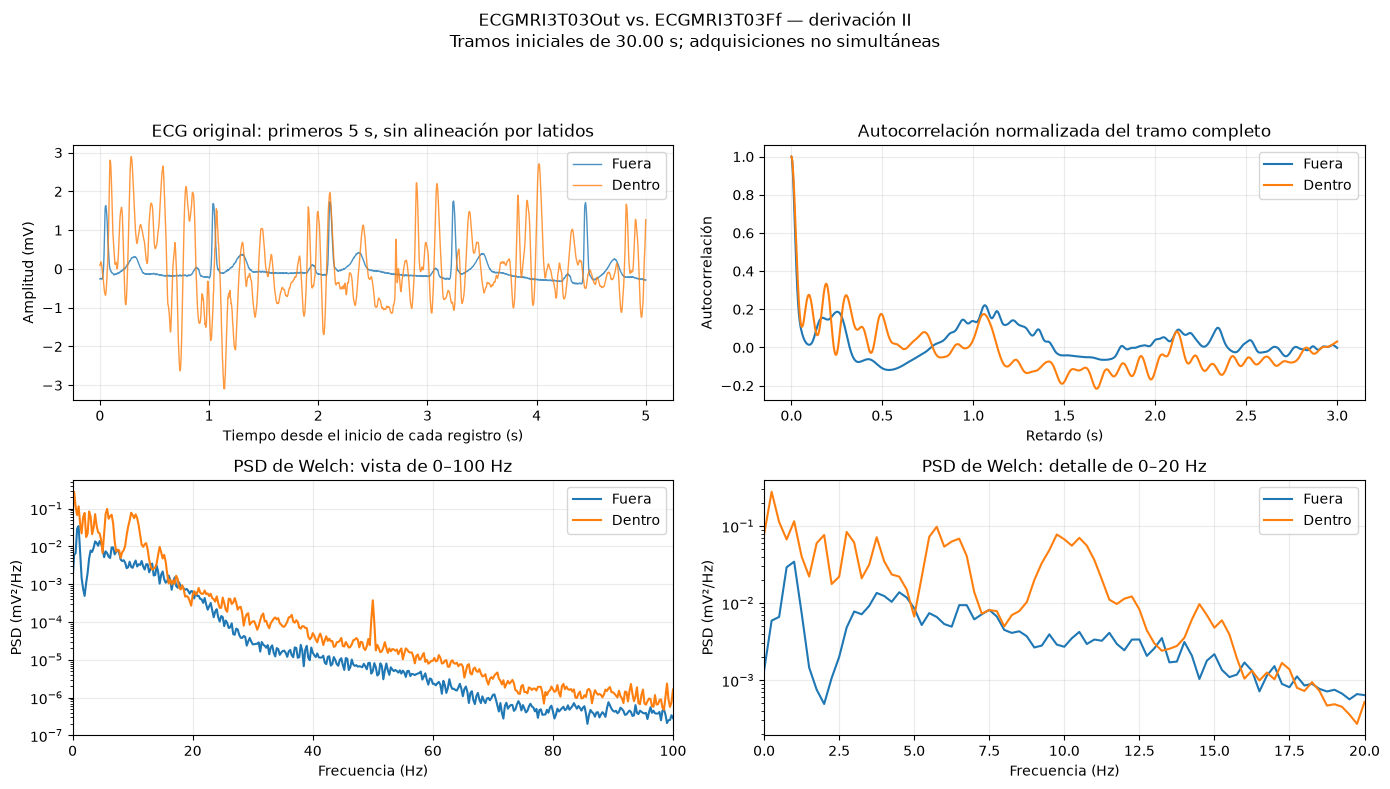

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,-0.0057,0.1012,0.3181,14
1,Dentro,30.0,0.0269,0.6390,0.7998,14


Comparación dentro–fuera: serie de 7 T


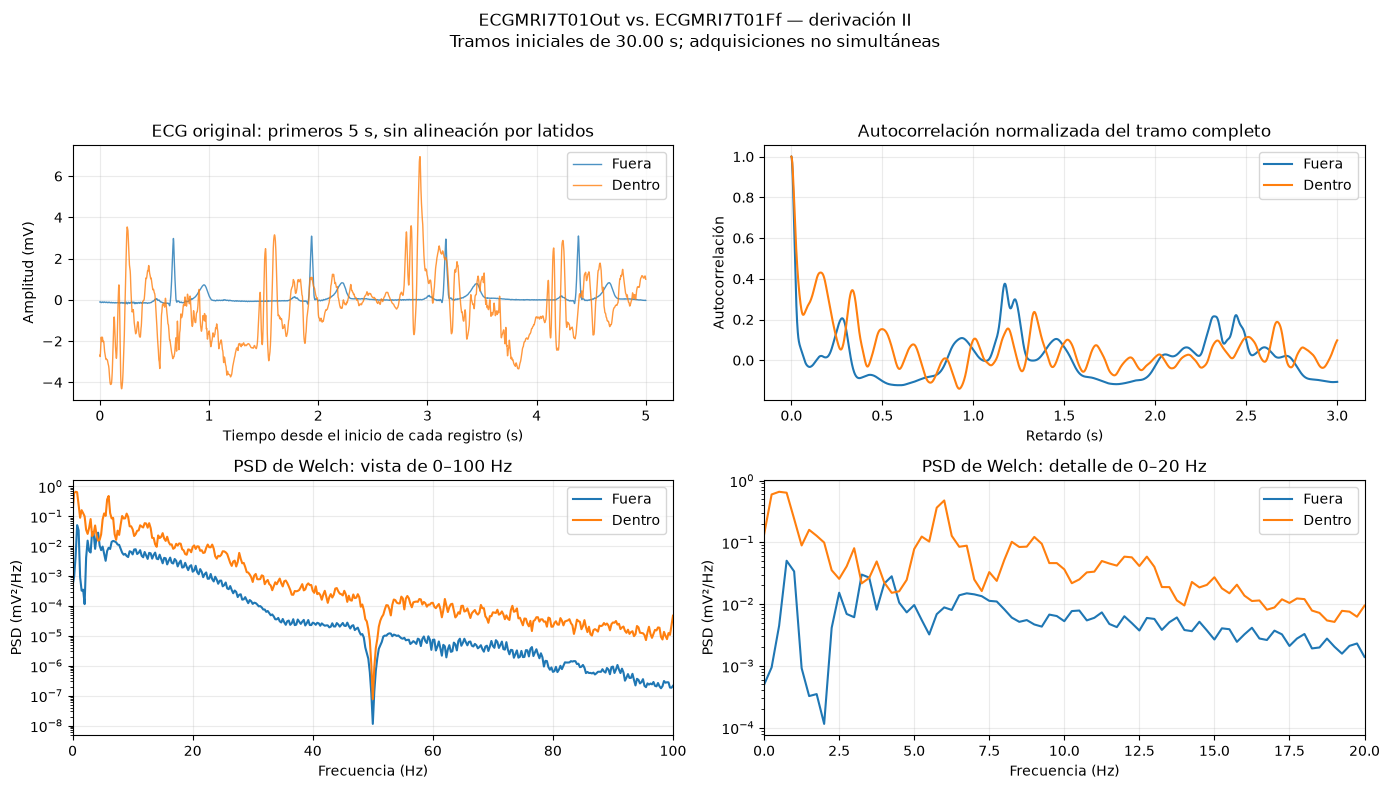

,Condición,Duración analizada (s),Media (mV),Varianza (mV²),RMS (mV),Segmentos Welch
0,Fuera,30.0,0.0467,0.1574,0.3995,14
1,Dentro,30.0,-0.0721,1.7909,1.3402,14


In [12]:
# La derivación II se utiliza como ejemplo de visualización.
# La caracterización general de la celda 2 incluye todas las derivaciones.

print("Comparación dentro–fuera: serie de 3 T")

comparacion_3t = comparar_registros(
    nombre_fuera="ECGMRI3T03Out",
    nombre_dentro="ECGMRI3T03Ff",
    derivacion="II",
)

display(comparacion_3t.round(4))


print("Comparación dentro–fuera: serie de 7 T")

comparacion_7t = comparar_registros(
    nombre_fuera="ECGMRI7T01Out",
    nombre_dentro="ECGMRI7T01Ff",
    derivacion="II",
)

display(comparacion_7t.round(4))

### Conclusión de la caracterización temporal y frecuencial

En los dos ejemplos analizados —3T03 y 7T01, derivación II—,
los registros adquiridos dentro del resonador presentan oscilaciones
de mayor amplitud y una morfología cardíaca menos claramente
reconocible que sus referencias externas.

Las autocorrelaciones conservan máximos compatibles con la repetición
de los ciclos cardíacos, pero muestran diferencias entre condiciones,
especialmente a retardos cortos. Por lo tanto, la presencia de
periodicidad no garantiza la preservación de la morfología del ECG.

En ambos pares, la PSD muestra una mayor potencia del registro
interno en amplias regiones del espectro, con diferencias destacadas
en bajas frecuencias. Estas diferencias se superponen con el contenido
frecuencial del ECG, lo que evidencia la dificultad de atenuarlas
mediante filtros convencionales sin modificar también componentes
cardíacas. El análisis espectral por sí solo no permite separar
la contribución del MHD de otras fuentes de interferencia.

También se observan comportamientos diferentes alrededor de 50 Hz:
un pico estrecho en el registro interno de 3T03 y una atenuación
marcada en ambos registros de 7T01. Esto indica que el tratamiento
de la interferencia de red debe considerar las características
de cada registro y su posible acondicionamiento previo.

Estas observaciones justifican comparar distintas estrategias
de filtrado y evaluar tanto su efecto sobre la detección de QRS
como sobre la morfología del ECG. Los resultados corresponden
a dos ejemplos y no permiten concluir que las diferencias sean
exclusivamente causadas por el MHD ni que aumenten con la intensidad
del campo, dado que se comparan sujetos distintos y adquisiciones
no simultáneas.

### Exploración del contenido espectral alrededor de 50 Hz

Para identificar picos o atenuaciones alrededor de 50 Hz, se calcula
un contraste espectral por registro y derivación:

$ C_{50} = 10 \log_{10}{(\frac{PSD media en (49–51 Hz)}{PSD media en bandas vecinas})} $ 

Como referencia local se utilizan las bandas 47–49 Hz y 51–53 Hz.
Los intervalos se implementan sin compartir bins entre bandas.

Un contraste positivo indica mayor densidad de potencia alrededor
de 50 Hz respecto de su entorno; un contraste negativo indica una
depresión relativa. Un valor próximo a cero indica niveles similares.

Las bandas son una elección exploratoria del trabajo. El indicador
no confirma por sí solo interferencia de red ni permite decidir
automáticamente la aplicación de un filtro notch.

Los resultados se representan mediante un mapa de calor por registro
y derivación, y mediante boxplots separados por condición de adquisición
y número de derivaciones. Los boxplots incluyen puntos individuales.

Cada punto representa una combinación registro–derivación.
Las derivaciones de un mismo registro no son observaciones independientes;
estas figuras se utilizan con fines descriptivos.

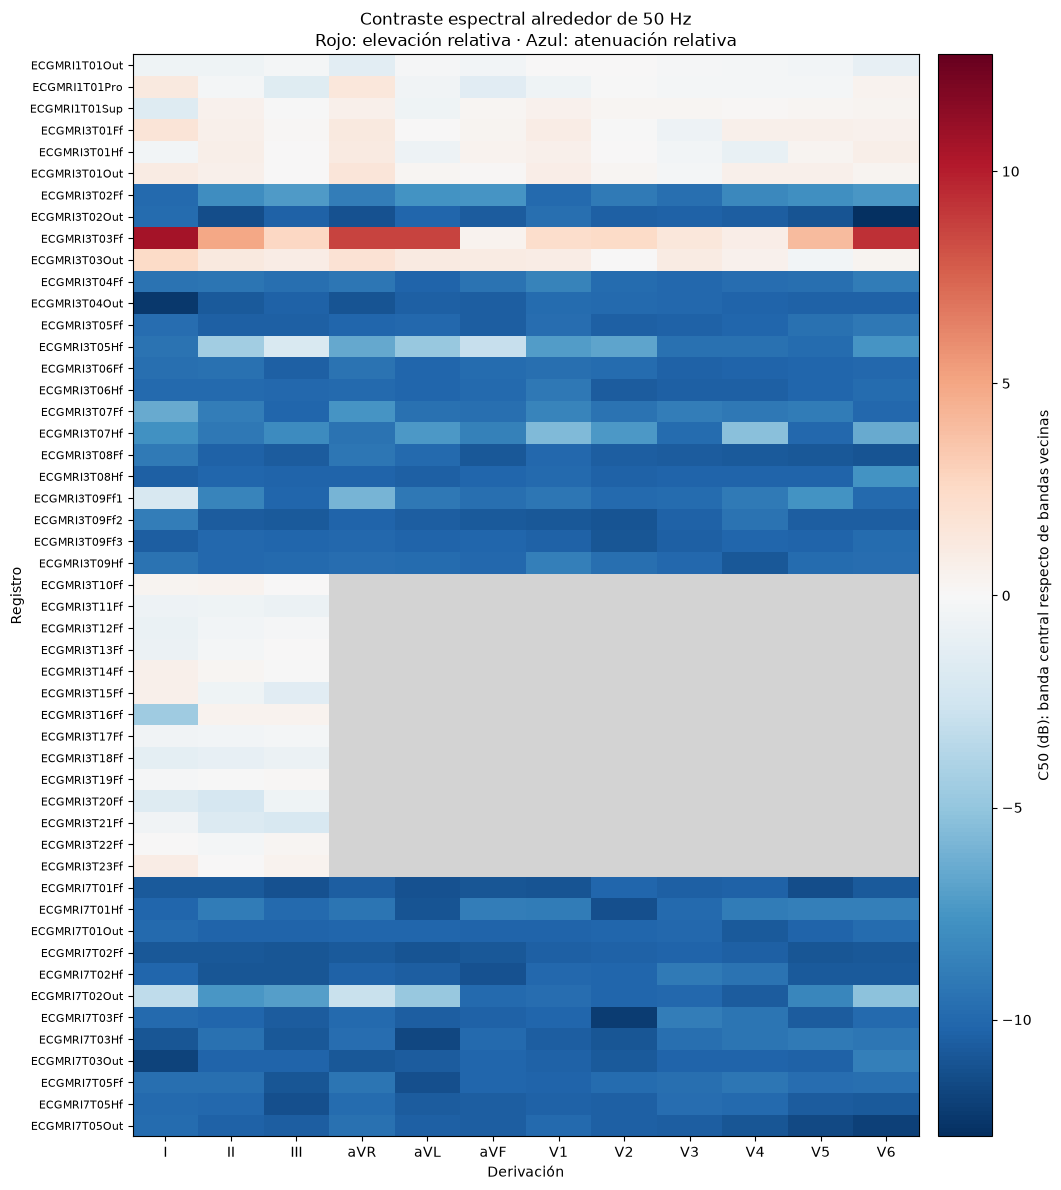

In [14]:
filas_50hz = []

for _, fila in caracteristicas.iterrows():
    nombre = fila["Registro"]
    derivacion = fila["Derivación"]

    espectro = espectros[(nombre, derivacion)]
    f = espectro["Frecuencia (Hz)"]
    psd = espectro["PSD (mV²/Hz)"]

    # Intervalos sin compartir bins:
    # central: [49, 51)
    # vecinas: [47, 49) y [51, 53)
    central = (f >= 49) & (f < 51)
    vecinas = (
        ((f >= 47) & (f < 49))
        | ((f >= 51) & (f < 53))
    )

    if not central.any() or not vecinas.any():
        raise ValueError(
            f"{nombre}, {derivacion}: faltan bins en las bandas."
        )

    media_central = np.mean(psd[central])
    media_vecinas = np.mean(psd[vecinas])

    # No se agrega una constante artificial a potencias nulas.
    if media_central > 0 and media_vecinas > 0:
        contraste = 10 * np.log10(media_central / media_vecinas)
    else:
        contraste = np.nan

    filas_50hz.append({
        "Registro": nombre,
        "Derivación": derivacion,
        "Condición": (
            "Dentro" if fila["Dentro del resonador"] else "Fuera"
        ),
        "PSD media 49–51 Hz": media_central,
        "PSD media vecinas": media_vecinas,
        "C50 (dB)": contraste,
    })

analisis_50hz = pd.DataFrame(filas_50hz)

# Incorporar la configuración de adquisición desde el inventario.
analisis_50hz = analisis_50hz.merge(
    registros_validos[["Registro", "Derivaciones"]],
    on="Registro",
    how="left",
    validate="many_to_one",
)

orden_derivaciones = [
    "I", "II", "III", "aVR", "aVL", "aVF",
    "V1", "V2", "V3", "V4", "V5", "V6",
]

presentes = analisis_50hz["Derivación"].unique()
orden_derivaciones = [
    d for d in orden_derivaciones if d in presentes
] + sorted(set(presentes) - set(orden_derivaciones))

orden_registros = sorted(analisis_50hz["Registro"].unique())

mapa_50hz = (
    analisis_50hz.pivot(
        index="Registro",
        columns="Derivación",
        values="C50 (dB)",
    )
    .reindex(index=orden_registros, columns=orden_derivaciones)
)

valores = mapa_50hz.to_numpy(dtype=float)
finitos = valores[np.isfinite(valores)]

if len(finitos) == 0:
    raise ValueError("No hay contrastes finitos para representar.")

# Escala simétrica: cero siempre representa igualdad con el entorno.
limite = max(float(np.max(np.abs(finitos))), 1.0)
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)

colores = plt.get_cmap("RdBu_r").copy()
colores.set_bad("lightgray")

fig, ax = plt.subplots(
    figsize=(11, max(7, 0.24 * len(mapa_50hz)))
)

imagen = ax.imshow(
    np.ma.masked_invalid(valores),
    aspect="auto",
    cmap=colores,
    norm=norma,
    interpolation="nearest",
)

ax.set_xticks(np.arange(len(mapa_50hz.columns)))
ax.set_xticklabels(mapa_50hz.columns)

ax.set_yticks(np.arange(len(mapa_50hz.index)))
ax.set_yticklabels(mapa_50hz.index, fontsize=8)

ax.set(
    title="Contraste espectral alrededor de 50 Hz\n"
          "Rojo: elevación relativa · Azul: atenuación relativa",
    xlabel="Derivación",
    ylabel="Registro",
)

barra = fig.colorbar(imagen, ax=ax, pad=0.02)
barra.set_label("C50 (dB): banda central respecto de bandas vecinas")

plt.tight_layout()
plt.show()

### Resultado de la exploración alrededor de 50 Hz

El contraste espectral muestra un comportamiento heterogéneo entre
registros. En buena parte de las adquisiciones de 12 derivaciones
predominan valores negativos, tanto dentro como fuera del resonador,
indicando una depresión de la PSD alrededor de 50 Hz respecto de
las bandas vecinas. Este patrón es compatible con un posible
filtrado previo, aunque no permite confirmar su presencia ni su origen.

El registro ECGMRI3T03Ff se distingue por presentar valores positivos
en casi todas sus derivaciones, consistentes con el pico próximo
a 50 Hz observado en la inspección de su PSD.

En los registros de tres derivaciones, los contrastes son generalmente
cercanos a cero, indicando un nivel espectral similar al entorno.
Esto no implica ausencia de interferencia de red.

Los resultados no respaldan aplicar automáticamente un filtro notch
a todos los registros. La decisión deberá considerar la inspección
espectral y la magnitud de la componente en cada caso.

In [16]:
# ============================================================
# Subgrupos según contraste espectral alrededor de 50 Hz
# ============================================================

UMBRAL_C50_DB = -5.0

clasificacion_50hz = analisis_50hz.copy()

# Comprobar que todas las combinaciones puedan clasificarse.
if not np.isfinite(clasificacion_50hz["C50 (dB)"]).all():
    raise ValueError(
        "Hay valores C50 no definidos. Revisarlos antes de crear los grupos."
    )

clasificacion_50hz["Grupo 50 Hz"] = np.where(
    clasificacion_50hz["C50 (dB)"] < UMBRAL_C50_DB,
    "Atenuación marcada",
    "Resto",
)

# Tablas para utilizar en los análisis posteriores.
subgrupos_50hz = {
    "atenuacion_marcada": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Atenuación marcada"
    ].copy(),

    "resto": clasificacion_50hz.loc[
        clasificacion_50hz["Grupo 50 Hz"] == "Resto"
    ].copy(),
}

# Listas de pares (registro, derivación) para cargar las señales.
pares_por_grupo_50hz = {
    grupo: list(zip(tabla["Registro"], tabla["Derivación"]))
    for grupo, tabla in subgrupos_50hz.items()
}

# Resumen.
resumen_subgrupos_50hz = pd.DataFrame([
    {
        "Grupo": grupo,
        "Combinaciones registro–derivación": len(tabla),
        "Registros distintos": tabla["Registro"].nunique(),
    }
    for grupo, tabla in subgrupos_50hz.items()
])

display(resumen_subgrupos_50hz)

# Distribución por condición y configuración de adquisición.
display(pd.crosstab(
    index=[
        clasificacion_50hz["Condición"],
        clasificacion_50hz["Derivaciones"],
    ],
    columns=clasificacion_50hz["Grupo 50 Hz"],
))

,Grupo,Combinaciones registro–derivación,Registros distintos
0,atenuacion_marcada,328,28
1,resto,146,25


Grupo 50 Hz             Atenuación marcada  Resto
Condición Derivaciones                           
Dentro    3                              0     42
          12                           259     65
Fuera     12                            69     39

Se dividieron las combinaciones registro–derivación en dos grupos:
atenuación marcada (C50 < −5 dB) y resto (C50 ≥ −5 dB).

El umbral de −5 dB es un criterio operativo exploratorio del trabajo:
corresponde a una PSD media central inferior a aproximadamente el
31,6 % de la PSD media de las bandas vecinas. No confirma la existencia
de un filtro previo.

Ambos grupos se conservan para analizarlos por separado cuando
corresponda. El grupo restante puede incluir señales con elevación,
nivel similar o atenuación menos marcada alrededor de 50 Hz.

La clasificación se realiza por derivación; un mismo registro puede
contener derivaciones pertenecientes a ambos grupos.